## **Lab 3: Spectral Representation**

The goal of this lab is to connect the time-domain signal you have been working with to its frequency-domain representation. The theory summary on spectrum representation introduces two complementary views of the same signal:

- the Fourier transform, which gives the frequency content of a signal segment, and
- the spectrogram, which shows how that content changes over time.

In this lab we will first compute the magnitude spectrum of a short fragment of the reference audio, then we will compute a spectrogram of the whole sound. The goal is not only to produce plots, but also to interpret them and relate them back to the sound you hear.

A periodic signal contains energy at its fundamental frequency and at its harmonics. When the signal is not perfectly periodic, the spectrum becomes less sharp and the energy spreads around those frequencies. In a short fragment, the FFT gives a snapshot of the dominant components. In a longer signal, the spectrogram shows how these components evolve over time.

In [38]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display

from util import load_audio, plot_signals, plot_spectrogram, plot_spectrum

We will use the same reference sound from the previous labs. If you have your own audio file in a cloned repository, you can point the path there; otherwise the notebook will use the bundled reference file.

### 1. Spectrum Analysis

This section show how to compute the spectrum and the spectrogram of a sound

In [39]:
# Clone your own repository and point reference_path to your own audio file.
# \!git clone https://github.com/your-username/sis1_name.git
# reference_path = Path('./sis1_name/your_file.wav')

reference_path = Path('audio/audio_arpa.wav')
reference_audio, fs = load_audio(reference_path)
print(f'Using audio file: {reference_path}')

display(Audio(reference_audio, rate=fs))

Using audio file: audio/audio_arpa.wav


#### 1.1 Fourier transform of a short fragment

The first step is to look at a short fragment of the sound and compute its magnitude spectrum using the FFT. This gives a snapshot of the strongest frequency components present in that fragment.

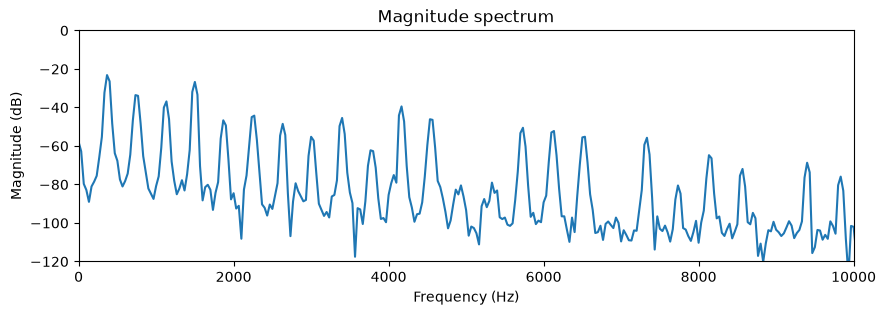

In [40]:
start = int(0.25 * fs)
end = int(0.28 * fs)
fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

#### 1.2 Questions

1. What are the strongest peaks in the magnitude spectrum? To what harmonics do they correspond?
   - The strongest peaks in the magnitude spectrum are the first ones, on the left of the graph. These correspond to the fundamental frequency and the first harmonics.

2. Do you see a fundamental frequency and its harmonics? How did you identify them? 
   - Yes. The fundamental frequency is the very first tall peak on the left. I identified the harmonics because they are the rest of the peaks that come after it.

3. How would the spectrum change if the fragment were taken from a different part of the signal?
   - If the fragment were taken from a different part of the signal, the peaks would be smaller because the volume of the sound goes down over time.

#### 1.3 Spectrogram of the whole sound

The FFT of one fragment gives a local snapshot, but a sound changes over time. A spectrogram shows how the frequency content evolves across the whole signal.

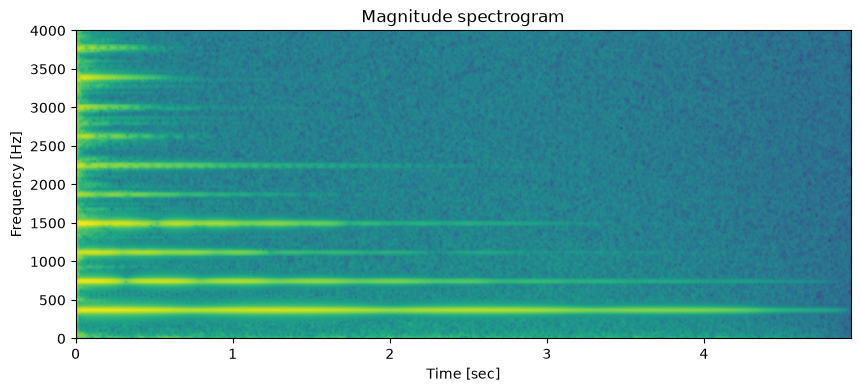

In [41]:
n_fft = 2048
hop_length = 256

ax = plot_spectrogram(reference_audio, sr=fs, N=n_fft, H=hop_length)
ax.set_ylim([0, 4000])
plt.show()

#### 1.4 Questions

1. Which frequencies are present for most of the sound? What does it mean from a perceptual point of view?
   - The lowest frequencies are present for most of the sound. This means that we hear the same musical note  pitch the whole time.

2. Do the bright bands stay fixed or do they change over time? What does it mean?
   - The bright bands stay at the same frequencies, but they fade out over time. The higher ones fade out faster. This means the pitch stays the same, but the volume drops and the sound gets softer.

3. How does the spectrogram help explain why the sound changes over time? Describe the sound evolution.
   - The spectrogram shows a lot of frequencies at the very beginning, but the high frequencies disappear quickly. The sound starts very strong and sharp, and then slowly fades away as only the lower frequencies remain.

#### 1.4 Fragment comparison

Repeat the spectral analysis for a different fragment of the signal and compare the magnitude spectra. Explain the difference.

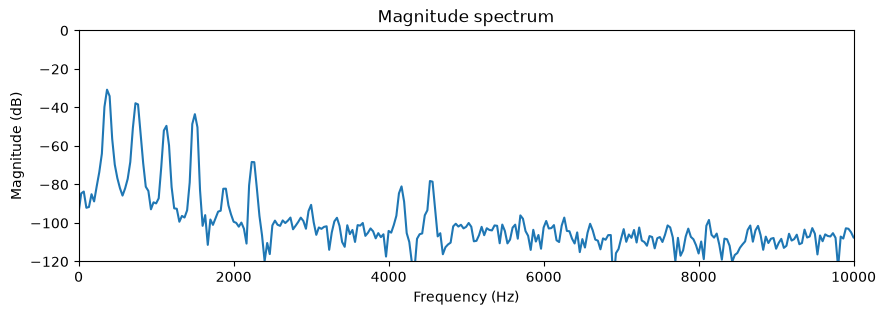

In [42]:
start2 = int(1.0 * fs) # i choose 1 second.
end2 = int(1.03 * fs)
fragment2 = reference_audio[start2:end2]

ax = plot_spectrum(fragment2, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

import matplotlib.pyplot as plt
plt.show()

The peaks in this second fragment are much smaller than the first one, and the peaks on the right side have disappeared completely. This is because the volume of the sound fades away over time, and the higher frequencies fade out faster than the lower ones.

Choose a time where several harmonics are visible in the spectrogram and plot the spectrum at that time. Can you explain the result?

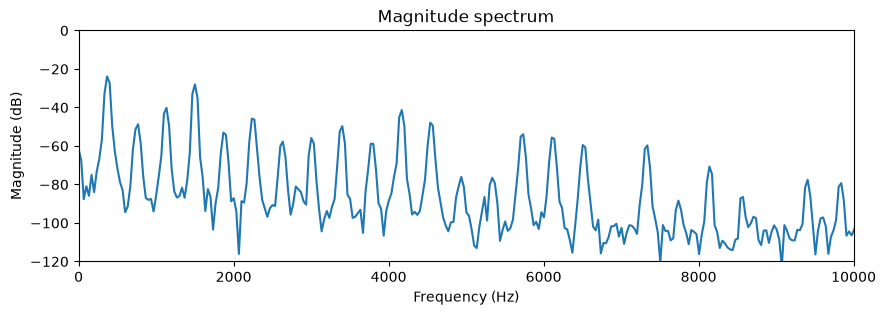

In [43]:
t_selected = 0.3 # I choose 0.3 seconds, so its a time early.
start3 = int(t_selected * fs)
end3 = int((t_selected + 0.03) * fs)
fragment3 = reference_audio[start3:end3]

ax = plot_spectrum(fragment3, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

At this time, we can see the fundamental frequency and multiple sharp harmonic peaks because the string is still vibrating strongly after being played. Each peak represents one of the frequencies that make up the harp sound before they fade out completely.

Use the plots to estimate the weights of the fundamental frequency and a few harmonics. Store them in a list for later use. Be careful because the amplitude of the plot are in dB and you will need them in a linear scale, from 0 to 1, where 1 should be the maximum value of the spectrum. So you need to perform the conversion from dB to linear.

In [44]:
db_peaks = [0, -18, -25, -35, -45] #the fundamental peak is near 0, and the next peaks get smaller
linear_weights = [10 ** (db / 20) for db in db_peaks]
max_val = max(linear_weights)
weights = [w / max_val for w in linear_weights]

print(weights)

[1.0, 0.12589254117941673, 0.05623413251903491, 0.01778279410038923, 0.005623413251903491]


### 2. Synthesis

Now we will use the harmonic synthesis idea from previous labs to build a signal from the estimated spectral weights.

In [45]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

#### 2.1 Write the code

Use the `synthesize` function to generate a signal with the weights from part 1.3 and the fundamental frequency and phase from earlier labs. Plot the synthesized signal together with the reference so you can compare them directly.

In [46]:
# Write the synthesis code here

In [47]:
# Write the plotting code here, both time domain and spectrogram

#### 2.2 Questions

1. What do you notice when you compare the synthesized spectrogram with the reference spectrogram?
   - Write your answer here.

2. Which parts of the sound are reproduced well, and which parts are still missing or different?
   - Write your answer here.